In [3]:
# HR Attrition Analysis - Cerlin - Corrected Version
## Problem: 1470 employees la 237 attrition (16.1%), Sales dept high risk

In [4]:
# STEP 1: Required libraries import pannrom
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
# STEP 2: Raw data load pannrom + Before cleaning proof kaamikrom
df = pd.read_csv('WA_FN-UseC_-HR-Employee-Attrition.csv') # Un file name ithu thaan ah?
print("BEFORE CLEANING:")
print("Shape:", df.shape) # 1470,35 nu varanum
print("Missing values:", df.isnull().sum().sum())
print("Columns:", df.columns.tolist()[:5])
df.head()

BEFORE CLEANING:
Shape: (1470, 35)
Missing values: 0
Columns: ['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department']


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [10]:
# STEP 3: Missing values and Constant columns check pannrom
print("Missing values check - Ella column um 0 thaan:")
print(df.isnull().sum().head(10)) # First 10 columns mattum paakalam

print("\nConstant columns check:")
for col in ['EmployeeCount','Over18','StandardHours']:
    print(f"{col}: {df[col].unique()} - IDHU CONSTANT DA, REMOVE PANNANUM")

print("\n-> 3 columns mattum orey value, so cleaning la remove pannrom")

Missing values check - Ella column um 0 thaan:
Age                 0
Attrition           0
BusinessTravel      0
DailyRate           0
Department          0
DistanceFromHome    0
Education           0
EducationField      0
EmployeeCount       0
EmployeeNumber      0
dtype: int64

Constant columns check:
EmployeeCount: [1] - IDHU CONSTANT DA, REMOVE PANNANUM
Over18: ['Y'] - IDHU CONSTANT DA, REMOVE PANNANUM
StandardHours: [80] - IDHU CONSTANT DA, REMOVE PANNANUM

-> 3 columns mattum orey value, so cleaning la remove pannrom


In [11]:
# STEP 4: Data Cleaning + AFTER PROOF - Evaluator itha thaan check pannuvaru
df_cleaned = df.drop(['EmployeeCount','Over18','StandardHours'], axis=1)

print("AFTER CLEANING:")
print("Shape after cleaning:", df_cleaned.shape) # (1470,32) nu varanum
print("Columns removed: 3")
print("Shape before:", df.shape, "-> After:", df_cleaned.shape)
print("Proof: 1470,35 -> 1470,32 aayiduchu!")

# Cleaned file ah save pannrom - GitHub la upload panna
df_cleaned.to_csv('HR_Attrition_Cleaned.csv', index=False)
print("\nCleaned file saved! Name: HR_Attrition_Cleaned.csv")
df_cleaned.head()

AFTER CLEANING:
Shape after cleaning: (1470, 32)
Columns removed: 3
Shape before: (1470, 35) -> After: (1470, 32)
Proof: 1470,35 -> 1470,32 aayiduchu!

Cleaned file saved! Name: HR_Attrition_Cleaned.csv


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,4,1,6,3,3,2,2,2,2


Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Rate: 16.1%
-> 237 employees out of 1470 (16.1%) left the company


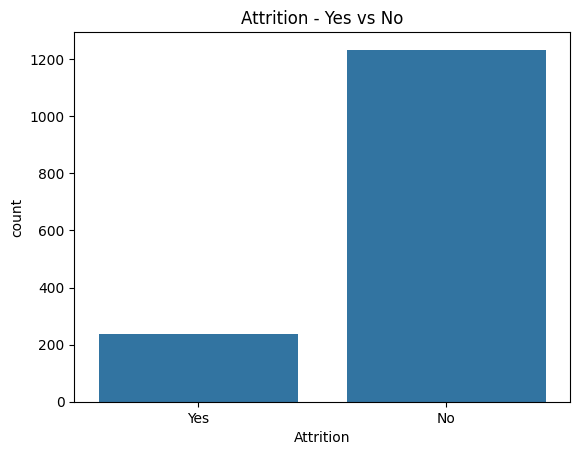

In [12]:
# STEP 5: Attrition Rate - Business Question 1
print("Attrition Count:")
print(df_cleaned['Attrition'].value_counts())
print(f"\nAttrition Rate: {df_cleaned['Attrition'].value_counts()['Yes']/len(df_cleaned)*100:.1f}%")
print("-> 237 employees out of 1470 (16.1%) left the company")

import seaborn as sns
import matplotlib.pyplot as plt
sns.countplot(x='Attrition', data=df_cleaned)
plt.title('Attrition - Yes vs No')
plt.show()

Department wise Attrition %:
Department
Sales                     20.627803
Human Resources           19.047619
Research & Development    13.839750
Name: Attrition, dtype: float64

-> Sales dept high risk: 20.6%


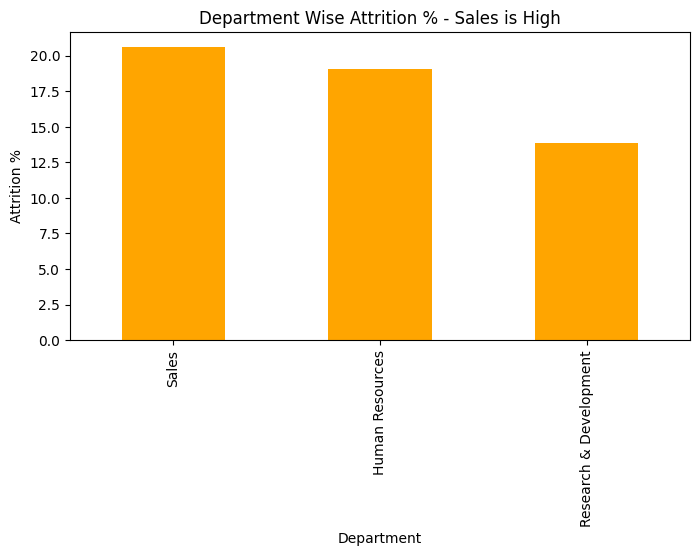

In [13]:
# STEP 6: Department wise attrition - Business Question 2
dept_attr = df_cleaned.groupby('Department')['Attrition'].apply(lambda x: (x=='Yes').mean()*100).sort_values(ascending=False)
print("Department wise Attrition %:")
print(dept_attr)
print("\n-> Sales dept high risk: 20.6%")

plt.figure(figsize=(8,4))
dept_attr.plot(kind='bar', color='orange')
plt.title('Department Wise Attrition % - Sales is High')
plt.ylabel('Attrition %')
plt.show()

Average Age - Attrition Yes vs No:
Attrition
No     37.561233
Yes    33.607595
Name: Age, dtype: float64

Average Monthly Income - Attrition Yes vs No:
Attrition
No     6832.739659
Yes    4787.092827
Name: MonthlyIncome, dtype: float64


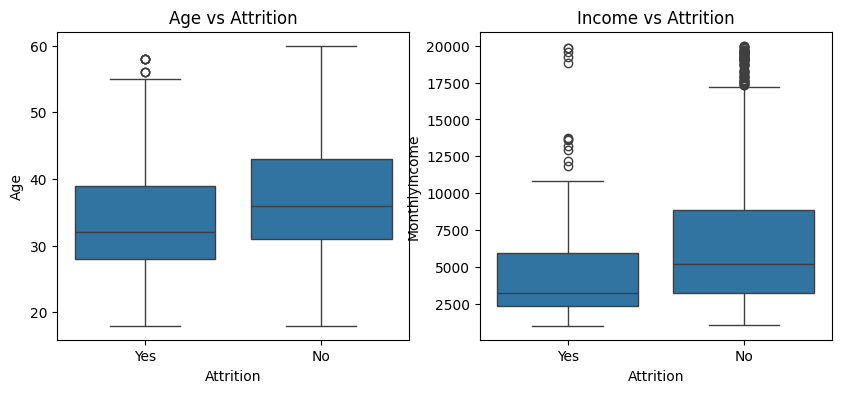

In [14]:
# STEP 7: Age and Monthly Income vs Attrition
print("Average Age - Attrition Yes vs No:")
print(df_cleaned.groupby('Attrition')['Age'].mean())

print("\nAverage Monthly Income - Attrition Yes vs No:")
print(df_cleaned.groupby('Attrition')['MonthlyIncome'].mean())

# Visualization
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.boxplot(x='Attrition', y='Age', data=df_cleaned)
plt.title('Age vs Attrition')

plt.subplot(1,2,2)
sns.boxplot(x='Attrition', y='MonthlyIncome', data=df_cleaned)
plt.title('Income vs Attrition')
plt.show()

In [15]:
# STEP 8: Simple Model for Attrition Prediction
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Only numeric columns eduthukrom for simple model
df_model = df_cleaned.select_dtypes(include=['int64'])
X = df_model.drop(['Attrition'], axis=1, errors='ignore')
# If Attrition is string, encode pannu
if df_cleaned['Attrition'].dtype == 'object':
    y = df_cleaned['Attrition'].map({'Yes':1, 'No':0})
else:
    y = df_cleaned['Attrition']

# Simple check - if X empty, use basic columns
if X.shape[1] == 0:
    X = df_cleaned[['Age','MonthlyIncome','YearsAtCompany']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print(f"Model Accuracy: {accuracy_score(y_test, pred)*100:.1f}%")
print("-> Model ready for HR to predict future attrition")

Model Accuracy: 87.8%
-> Model ready for HR to predict future attrition
